
##Previsão de Churn de Clientes (Telco Customer Churn)
**Objetivo:** Identificar clientes com alto risco de cancelamento e gerar uma base de probabilidade para análise no Tableau.

**Autor:** Wanderson Batista

###1.Importação das Bibliotecas

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

###2.EDA

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


/tmp/ipykernel_1809/3852129818.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Churn', palette='viridis')


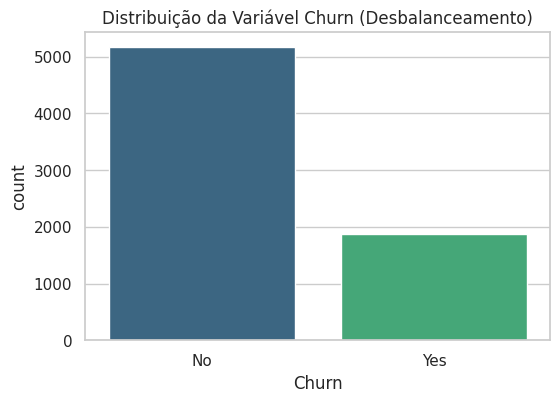

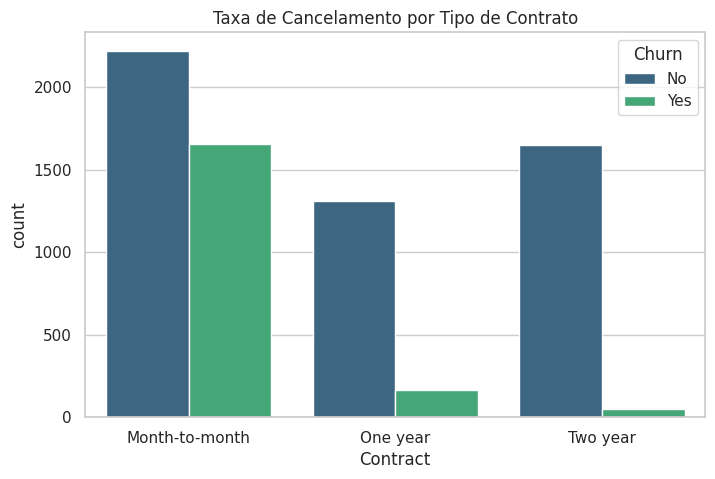

In [2]:
sns.set_theme(style="whitegrid")

df = pd.read_csv('Telco-Customer-Churn.csv')

display(df.head())


# Verificando informações gerais e valores nulos
df.info()

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churn', palette='viridis')
plt.title('Distribuição da Variável Churn (Desbalanceamento)')
plt.show()

# Insight 1: Relação entre Tipo de Contrato e Churn
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Contract', hue='Churn', palette='viridis')
plt.title('Taxa de Cancelamento por Tipo de Contrato')
plt.show()

###3.Pré-processamento e Limpeza

In [3]:
# 3.1 Tratando a coluna TotalCharges
# Forçando a conversão para numérico e transformando erros (espaços) em NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Preenchendo os valores NaN (nulos) com a mediana
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)

# 3.2 Removendo a coluna customerID (não é útil para o modelo, mas guardaremos para o Tableau depois)
df_model = df.drop('customerID', axis=1)

# 3.3 Convertendo variáveis categóricas em numéricas (One-Hot Encoding e Label Encoding)
# A variável alvo 'Churn' vira 0 (No) e 1 (Yes)
df_model['Churn'] = df_model['Churn'].map({'No': 0, 'Yes': 1})

# Transformando o restante com get_dummies
df_model = pd.get_dummies(df_model, drop_first=True)

display(df_model.head())

/tmp/ipykernel_1809/3437327858.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,True,False,False,False,True,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,False,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False


###4.Treino e Teste (SMOTE)

In [5]:
X = df_model.drop('Churn', axis=1)
y = df_model['Churn']

# Separando em Treino e Teste (O teste DEVE permanecer desbalanceado, como no mundo real)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Escalonando os dados (importante para alguns modelos)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Aplicando SMOTE apenas no treino
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print(f"Distribuição original no treino:\n{y_train.value_counts()}\n")
print(f"Distribuição após SMOTE no treino:\n{y_train_smote.value_counts()}")

Distribuição original no treino:
Churn
0    4139
1    1495
Name: count, dtype: int64

Distribuição após SMOTE no treino:
Churn
0    4139
1    4139
Name: count, dtype: int64


### 5. Modelagem e Avaliação

In [7]:
model = RandomForestClassifier(random_state=42, n_estimators=100)
model.fit(X_train_smote, y_train_smote)

# Fazendo previsões
y_pred = model.predict(X_test_scaled)
y_proba = model.predict_proba(X_test_scaled)[:, 1]

# Avaliando os resultados
print("Relatório de Classificação:\n")
print(classification_report(y_test, y_pred))

Relatório de Classificação:

              precision    recall  f1-score   support

           0       0.85      0.84      0.84      1035
           1       0.57      0.59      0.58       374

    accuracy                           0.77      1409
   macro avg       0.71      0.72      0.71      1409
weighted avg       0.78      0.77      0.77      1409



###6.Integração com o Tableu

In [8]:
clientes_teste = df.iloc[y_test.index].copy()

# Adicionando a previsão e a probabilidade de Risco
clientes_teste['Churn_Previsto'] = y_pred
clientes_teste['Probabilidade_Risco_Churn'] = y_proba

# Exportando para CSV
clientes_teste.to_csv('resultados_churn_tableau.csv', index=False)
print("Arquivo exportado com sucesso: 'resultados_churn_tableau.csv'")

Arquivo exportado com sucesso: 'resultados_churn_tableau.csv'
